<a href="https://colab.research.google.com/github/e2458115-hash/fes-traffic-game/blob/main/colab-engine/01_campus_map_extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q osmnx networkx matplotlib

OpenStreetMapから大学周辺の道路・歩道ネットワークを取得中...
ネットワークのボトルネック（媒介中心性）を解析中...


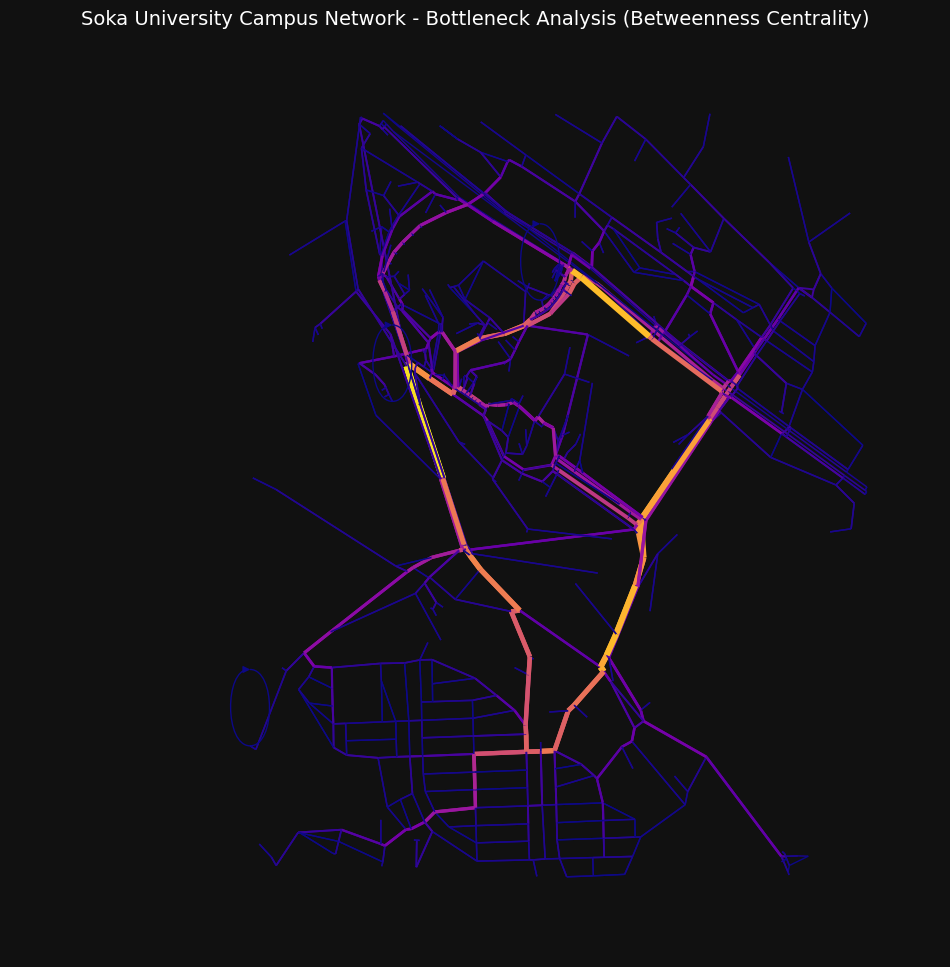

完了！ノード数: 724, エッジ数: 1957
'soka_campus_graph.json' が保存されました。左側のフォルダアイコンからダウンロードできます。


In [5]:
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import json

# 1. 大学の中心座標と取得半径（800m）を設定
center_point = (35.6881, 139.3275)  # 大学キャンパス中心付近
dist_meters = 800

print("OpenStreetMapから大学周辺の道路・歩道ネットワークを取得中...")
# network_type="all" で構内道路・歩道・車道をすべて取得
G = ox.graph_from_point(center_point, dist=dist_meters, network_type="all", simplify=True)

# 2. ネットワーク理論：エッジの「媒介中心性（Betweenness Centrality）」を計算
# （どの道路が閉鎖・混雑するとキャンパス全体の移動が麻痺するかのボトルネック指標）
print("ネットワークのボトルネック（媒介中心性）を解析中...")
G_digraph = nx.DiGraph(G)  # 多重辺を標準の有向グラフへ整理
edge_centrality = nx.edge_betweenness_centrality(G_digraph, weight="length")

# 計算結果を各道路（エッジ）の属性として保存
nx.set_edge_attributes(G_digraph, edge_centrality, "centrality")

# 3. 道路の混雑度（媒介中心性）に応じた色分けで可視化
fig, ax = plt.subplots(figsize=(12, 12), facecolor="#111111")
ax.set_facecolor("#111111")

# 中心性が高い道路ほど赤〜黄色く光るように色を設定
centralities = [G_digraph.edges[e].get("centrality", 0) for e in G_digraph.edges]
max_c = max(centralities) if max(centralities) > 0 else 1
edge_colors = [plt.cm.plasma(c / max_c) for c in centralities]
edge_widths = [1.0 + 4.0 * (c / max_c) for c in centralities]

nx.draw_networkx_edges(
    G_digraph,
    pos={n: (d["x"], d["y"]) for n, d in G_digraph.nodes(data=True)},
    ax=ax,
    edge_color=edge_colors,
    width=edge_widths,
    arrows=False
)
plt.title("Soka University Campus Network - Bottleneck Analysis (Betweenness Centrality)", color="white", fontsize=14)
plt.axis("off")
plt.show()

# 4. VS Code（Goサーバー）で読み込むためのクリーンなJSONデータに変換・保存
export_data = {
    "metadata": {
        "location": "Soka University Campus",
        "center": {"lat": center_point[0], "lon": center_point[1]},
        "node_count": G_digraph.number_of_nodes(),
        "edge_count": G_digraph.number_of_edges(),
        "attribution": "© OpenStreetMap contributors"
    },
    "nodes": [],
    "edges": []
}

for node_id, data in G_digraph.nodes(data=True):
    export_data["nodes"].append({
        "id": str(node_id),
        "lat": data["y"],
        "lon": data["x"]
    })

for u, v, data in G_digraph.edges(data=True):
    # 道路種別（歩道か車道かなど）を取得
    highway_type = data.get("highway", "unclassified")
    if isinstance(highway_type, list):
        highway_type = highway_type[0]

    export_data["edges"].append({
        "from": str(u),
        "to": str(v),
        "length_m": round(data.get("length", 10.0), 2),
        "highway": highway_type,
        "centrality": round(data.get("centrality", 0.0), 6),
        "capacity": 20 if highway_type in ["service", "residential", "unclassified"] else 5
    })

output_filename = "soka_campus_graph.json"
with open(output_filename, "w", encoding="utf-8") as f:
    json.dump(export_data, f, ensure_ascii=False, indent=2)

print(f"完了！ノード数: {len(export_data['nodes'])}, エッジ数: {len(export_data['edges'])}")
print(f"'{output_filename}' が保存されました。左側のフォルダアイコンからダウンロードできます。")

In [6]:
!pip install -q folium

import folium
import matplotlib.colors as mcolors

# 1. 創価大学中心を基準に本物の地図（OpenStreetMap）を生成
m = folium.Map(
    location=[center_point[0], center_point[1]],
    zoom_start=16,
    tiles="OpenStreetMap"  # 実際の地図タイルを背景に表示
)

# 2. 抽出したネットワークとボトルネック（媒介中心性）を地図の上に重ねて描画
centralities = [G_digraph.edges[e].get("centrality", 0) for e in G_digraph.edges]
max_c = max(centralities) if max(centralities) > 0 else 1

for u, v, data in G_digraph.edges(data=True):
    u_node = G_digraph.nodes[u]
    v_node = G_digraph.nodes[v]
    c = data.get("centrality", 0)
    ratio = c / max_c

    # 中心性が高い道路ほど赤く太く表示、低い道路は青く細く表示
    color = mcolors.to_hex(plt.cm.plasma(ratio))
    weight = 2 + 6 * ratio
    highway_type = data.get("highway", "unknown")

    folium.PolyLine(
        locations=[[u_node["y"], u_node["x"]], [v_node["y"], v_node["x"]]],
        color=color,
        weight=weight,
        opacity=0.85,
        tooltip=f"道路種別: {highway_type} / ボトルネック度: {c:.4f} / 長さ: {data.get('length', 0):.1f}m"
    ).add_to(m)

# 3. 地図を表示（マウスで拡大・縮小・移動可能）
m

In [7]:
import folium
import matplotlib.colors as mcolors

# 背景地図を制限のない「CartoDB positron」に変更
m = folium.Map(
    location=[center_point[0], center_point[1]],
    zoom_start=16,
    tiles="CartoDB positron"
)

centralities = [G_digraph.edges[e].get("centrality", 0) for e in G_digraph.edges]
max_c = max(centralities) if max(centralities) > 0 else 1

for u, v, data in G_digraph.edges(data=True):
    u_node = G_digraph.nodes[u]
    v_node = G_digraph.nodes[v]
    c = data.get("centrality", 0)
    ratio = c / max_c

    color = mcolors.to_hex(plt.cm.plasma(ratio))
    weight = 2 + 6 * ratio
    highway_type = data.get("highway", "unknown")

    folium.PolyLine(
        locations=[[u_node["y"], u_node["x"]], [v_node["y"], v_node["x"]]],
        color=color,
        weight=weight,
        opacity=0.85,
        tooltip=f"道路種別: {highway_type} / ボトルネック度: {c:.4f} / 長さ: {data.get('length', 0):.1f}m"
    ).add_to(m)

m

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [8]:
import folium
import matplotlib.colors as mcolors

# Esriの無料公開タイル（APIキー不要・Colab制限なし）を使用
esri_tiles = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"
esri_attr = "Tiles © Esri"

m = folium.Map(
    location=[center_point[0], center_point[1]],
    zoom_start=16,
    tiles=esri_tiles,
    attr=esri_attr
)

centralities = [G_digraph.edges[e].get("centrality", 0) for e in G_digraph.edges]
max_c = max(centralities) if max(centralities) > 0 else 1

for u, v, data in G_digraph.edges(data=True):
    u_node = G_digraph.nodes[u]
    v_node = G_digraph.nodes[v]
    c = data.get("centrality", 0)
    ratio = c / max_c

    # 中心性が高い道路ほど赤く太く表示、低い道路は青く細く表示
    color = mcolors.to_hex(plt.cm.plasma(ratio))
    weight = 2 + 6 * ratio
    highway_type = data.get("highway", "unknown")

    folium.PolyLine(
        locations=[[u_node["y"], u_node["x"]], [v_node["y"], v_node["x"]]],
        color=color,
        weight=weight,
        opacity=0.85,
        tooltip=f"道路種別: {highway_type} / ボトルネック度: {c:.4f} / 長さ: {data.get('length', 0):.1f}m"
    ).add_to(m)

# 地図を表示（マウスで拡大・縮小・移動可能）
m